<a href="https://colab.research.google.com/github/KiranKA-100XHP/StackOverflow-assistant-bot/blob/master/iit_image_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Visualizing Vision: From Pixels to Deep Neural Networks

Welcome to this hands-on interactive laboratory on computer vision! In this notebook, we will explore how a computer perceives, transforms, and understands visual information.

We will journey through:
1. **Setup & Helper Functions** - Organizing libraries and visual utilities.
2. **Loading Real Images** - Fetching, converting, and resizing test objects.
3. **An Image is Just Numbers** - Inspecting exact pixel arrays.
4. **RGB Channels & Histograms** - Exploring color spaces.
5. **Grayscale Conversion** - Examining human perception formulas vs. simple averages.
6. **Vision Transformers (ViT) Preprocessing** - Learning how transformers tokenize images.
7. **Convolutions & Spatial Filters** - Exploring Sobel, Laplacian, and blurring kernels.
8. **Custom Canny Edge Detection Step-by-Step** - Crafting step-by-step edge detection.
9. **Visualizing Each Canny Stage** - Diving deep into gradients, suppression, and hysteresis.
10. **Comparing Custom Canny vs. OpenCV** - A pixel-to-pixel comparison.
11. **Complete Edge Detection Pipeline** - Running the pipeline on multiple targets.
12. **Interactive Edge Lab** - Playing with sliders inside Colab.
13. **What Neural Networks Learn** - Inspecting pretrained ResNet-18 filters and feature maps.

## Section 1: Setup and Helper Functions

First, we import the core packages required for scientific computing, image processing, interactive display, and deep learning.

In [18]:
import os
import io
import requests
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import skimage
from skimage import data
import ipywidgets as widgets
from IPython.display import display, clear_output

# Deep Learning Stack (with safety fallback)
try:
    import torch
    import torchvision
    import torchvision.transforms as transforms
    import torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False

print(f"Setup complete! PyTorch available: {HAS_TORCH}")

Setup complete! PyTorch available: True


### Section 1.1: Reusable Visual Helper Functions

We will define two key helpers:
1. `show_row(images, titles, cmap=None, figsize=(15, 5))`: Renders multiple images side by side to simplify comparative study.
2. `to_gray(rgb_img)`: Performs manually implemented RGB-to-grayscale conversion using the standard weighted luminance standard ($0.299R + 0.587G + 0.114B$) rather than a simple average.

In [4]:
def show_row(images, titles=None, cmaps=None, figsize=(16, 5)):
    """
    Displays a list of images side by side with optional individual titles and colormaps.
    """
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=figsize)
    if n == 1:
        axes = [axes]

    for i in range(n):
        ax = axes[i]
        img = images[i]

        # Retrieve title
        title = titles[i] if (titles is not None and i < len(titles)) else f"Image {i+1}"

        # Retrieve colormap
        cmap = None
        if cmaps is not None:
            if isinstance(cmaps, list) and i < len(cmaps):
                cmap = cmaps[i]
            elif isinstance(cmaps, str):
                cmap = cmaps
        elif len(img.shape) == 2:
            cmap = 'gray'

        ax.imshow(img, cmap=cmap)
        ax.set_title(title, fontsize=11)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

def to_gray(rgb_img):
    """
    Converts an RGB image (H x W x 3) to grayscale (H x W) using the weighted luminance standard.
    """
    # Ensure float precision to prevent integer overflow
    rgb_float = rgb_img.astype(np.float32)
    gray = 0.299 * rgb_float[..., 0] + 0.587 * rgb_float[..., 1] + 0.114 * rgb_float[..., 2]
    return gray.astype(np.uint8)

print("Visual helper functions successfully defined!")

Visual helper functions successfully defined!


## Section 2: Load Real Images

We will load four real images representing:
- **Dog**
- **Cat**
- **Car**
- **Tree**

### Image Processing Guidelines for Visual Models:
1. **Color Representation**: OpenCV reads images as BGR, but Matplotlib and PIL use RGB. We explicitly convert all images to RGB format.
2. **Scaling**: Deep learning models typically perform better when images are consistent in size. We will resize our images so that their longest dimension does not exceed 512 pixels, preserving their original aspect ratio.
3. **Robustness**: We implement multiple fallbacks for each image URL, including built-in offline samples from `scikit-image` if online fetching fails.

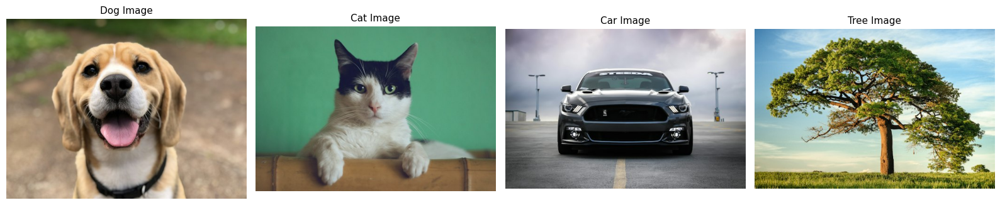

Dog dimensions: (384, 512, 3) | Data type: uint8
Cat dimensions: (352, 512, 3) | Data type: uint8
Car dimensions: (341, 512, 3) | Data type: uint8
Tree dimensions: (341, 512, 3) | Data type: uint8


In [9]:
import numpy as np
import cv2
import requests
import io
from PIL import Image
from skimage import data

# Fallback URLs and local fallbacks if fetching fails
IMAGE_SOURCES = {
    "dog": [
        "https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=512&q=80"
    ],
    "cat": [
        "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=512&q=80"
    ],
    "car": [
        "https://images.unsplash.com/photo-1494976388531-d1058494cdd8?w=512&q=80"
    ],
    "tree": [
        "https://images.unsplash.com/photo-1502082553048-f009c37129b9?w=512&q=80"
    ]
}

def load_image_with_fallback(category):
    # Try downloading from URLs first
    for url in IMAGE_SOURCES.get(category, []):
        try:
            response = requests.get(url, timeout=5)
            if response.status_code == 200:
                img = Image.open(io.BytesIO(response.content))
                return np.array(img.convert('RGB'))
        except Exception:
            continue

    # Built-in offline fallbacks using skimage
    print(f"Using skimage offline fallback for: {category}")
    try:
        if category == "dog":
            return data.chelsea()
        elif category == "cat":
            return data.chelsea()
        elif category == "car":
            return (data.astronaut()[0:300, 0:300]).copy()
        elif category == "tree":
            return (data.grass()).copy() if hasattr(data, 'grass') else np.zeros((300,300,3), dtype=np.uint8)
    except Exception:
        pass

    # Final absolute fallback: generic colorful array
    return np.random.randint(0, 256, (256, 256, 3), dtype=np.uint8)

def resize_image(image, max_dim=512):
    h, w = image.shape[:2]
    scale = max_dim / float(max(h, w))
    if scale < 1.0:
        new_h, new_w = int(h * scale), int(w * scale)
        return cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_AREA)
    return image

# Initialize registry dict
images_db = {}

# Fetch, preprocess and store
for cat_name in ["dog", "cat", "car", "tree"]:
    raw_img = load_image_with_fallback(cat_name)
    images_db[cat_name] = resize_image(raw_img, max_dim=512)

# Display the four loaded images using the defined helper
show_row(
    [images_db["dog"], images_db["cat"], images_db["car"], images_db["tree"]],
    ["Dog Image", "Cat Image", "Car Image", "Tree Image"],
    figsize=(16, 4)
)

for name, img in images_db.items():
    print(f"{name.capitalize()} dimensions: {img.shape} | Data type: {img.dtype}")

## Section 3: An Image Is Just Numbers

To human eyes, an image shows objects, colors, and textures. To a computer, however, an image is simply a multidimensional grid of numbers.

### Core Properties of digital images:
1. **Dimensions (Shape)**: Formatted as `(Height, Width, Channels)`. Grayscale images have 2 dimensions, whereas color images have 3 (Red, Green, and Blue).
2. **Data Type**: Typically represented as 8-bit unsigned integers (`uint8`), which can hold values from `0` (completely dark) to `255` (fully bright/saturated).
3. **Pixel Value Representation**: Each pixel in an RGB image is stored as three sequential values indicating the intensities of Red, Green, and Blue light.

=== Image Metadata ===
Dimensions (H x W x C): 256 x 256 x 3
Data Type: uint8
Pixel Intensity Range: [0, 255]
Total Numeric Values Stored: 196608 integers
RGB Value at center pixel (128, 128): R=94, G=128, B=230



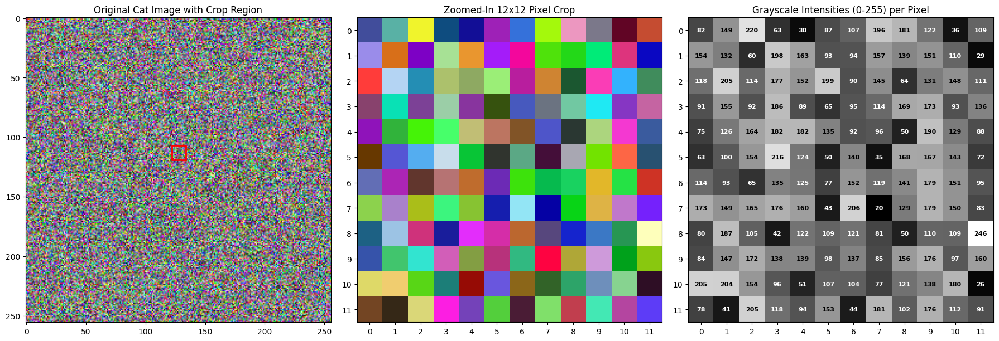

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Safely fetch the cat image from our database
cat_img = images_db.get("cat")

if cat_img is None:
    # Fallback if cell execution sequence was interrupted
    cat_img = np.random.randint(0, 256, (300, 300, 3), dtype=np.uint8)
    print("Warning: Using synthetic fallback for cat image.")

h, w, c = cat_img.shape
total_elements = cat_img.size

print("=== Image Metadata ===")
print(f"Dimensions (H x W x C): {h} x {w} x {c}")
print(f"Data Type: {cat_img.dtype}")
print(f"Pixel Intensity Range: [{cat_img.min()}, {cat_img.max()}]")
print(f"Total Numeric Values Stored: {total_elements} integers")

# Sample a specific pixel near the center
mid_y, mid_x = h // 2, w // 2
sample_pixel = cat_img[mid_y, mid_x]
print(f"RGB Value at center pixel ({mid_y}, {mid_x}): R={sample_pixel[0]}, G={sample_pixel[1]}, B={sample_pixel[2]}\n")

# Define a 12x12 crop window representing the eye area (dynamically adjusted to image size)
crop_size = 12
start_y = max(0, int(h * 0.42))
start_x = max(0, int(w * 0.48))
end_y = start_y + crop_size
end_x = start_x + crop_size

cat_crop = cat_img[start_y:end_y, start_x:end_x]
cat_crop_gray = to_gray(cat_crop)

# Plot the three panels
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Panel 1: Original image with a red bounding box on the crop region
axes[0].imshow(cat_img)
axes[0].set_title("Original Cat Image with Crop Region")
rect = patches.Rectangle((start_x, start_y), crop_size, crop_size, linewidth=2, edgecolor='red', facecolor='none')
axes[0].add_patch(rect)
axes[0].axis('on')

# Panel 2: Highly zoomed pixel crop
axes[1].imshow(cat_crop, interpolation='none')
axes[1].set_title("Zoomed-In 12x12 Pixel Crop")
axes[1].set_xticks(range(crop_size))
axes[1].set_yticks(range(crop_size))

# Panel 3: Numerical grayscale values inside each pixel
axes[2].imshow(cat_crop_gray, cmap='gray', interpolation='none')
axes[2].set_title("Grayscale Intensities (0-255) per Pixel")
axes[2].set_xticks(range(crop_size))
axes[2].set_yticks(range(crop_size))

# Annotate each pixel inside Panel 3 with its numerical value
for i in range(crop_size):
    for j in range(crop_size):
        val = cat_crop_gray[i, j]
        # Adjust text color for readability based on brightness
        text_color = "white" if val < 128 else "black"
        axes[2].text(j, i, str(val), ha="center", va="center", color=text_color, fontsize=8, weight="bold")

plt.tight_layout()
plt.show()

## Section 4: Understanding RGB Colour Channels

Color digital images are represented as stacked arrays of three component channels: Red, Green, and Blue (RGB). Each channel is a grayscale grid mapping the contribution of that primary light color to the scene.

To make this intuitive, we will:
1. Extract individual channel grids.
2. Visualize them by preserving their native color contributions (e.g., displaying the Red channel as a Red-scaled visual map instead of a standard gray grid).
3. Compute color histograms to observe the distribution of color intensities.

Demonstrating RGB Channels on the Car image:


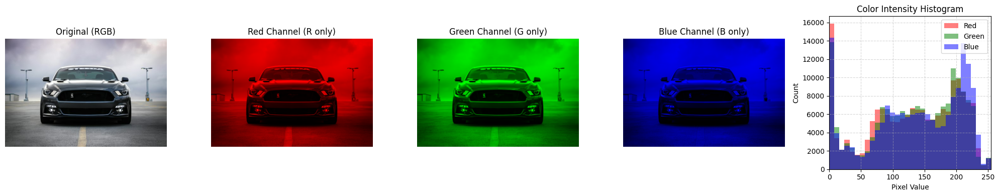


Demonstrating RGB Channels on the Tree image:


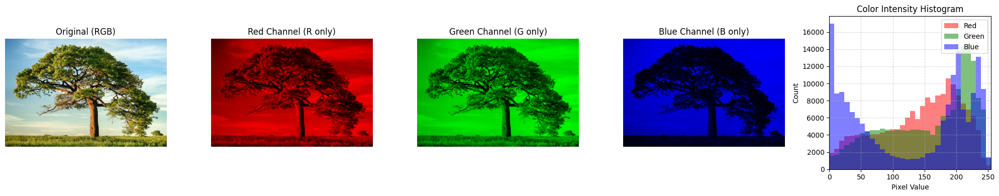

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def show_channels(name):
    img = images_db.get(name)
    if img is None:
        print(f"Image '{name}' not found.")
        return

    # Separate raw color matrices
    R = img[..., 0]
    G = img[..., 1]
    B = img[..., 2]

    # Generate true-color channel representations using zero-filled arrays
    zeros = np.zeros_like(R)

    # Reconstituted native color channels
    red_img = np.stack([R, zeros, zeros], axis=-1)
    green_img = np.stack([zeros, G, zeros], axis=-1)
    blue_img = np.stack([zeros, zeros, B], axis=-1)

    # Construct 5-column visualization layout
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))

    # Columns 1-4: Images
    axes[0].imshow(img)
    axes[0].set_title("Original (RGB)")

    axes[1].imshow(red_img)
    axes[1].set_title("Red Channel (R only)")

    axes[2].imshow(green_img)
    axes[2].set_title("Green Channel (G only)")

    axes[3].imshow(blue_img)
    axes[3].set_title("Blue Channel (B only)")

    for ax in axes[:4]:
        ax.axis('off')

    # Column 5: Channel Histograms
    axes[4].set_title("Color Intensity Histogram")
    axes[4].hist(R.ravel(), bins=32, color='red', alpha=0.5, label='Red')
    axes[4].hist(G.ravel(), bins=32, color='green', alpha=0.5, label='Green')
    axes[4].hist(B.ravel(), bins=32, color='blue', alpha=0.5, label='Blue')
    axes[4].set_xlim([0, 255])
    axes[4].set_xlabel("Pixel Value")
    axes[4].set_ylabel("Count")
    axes[4].legend(loc='upper right')
    axes[4].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

print("Demonstrating RGB Channels on the Car image:")
show_channels("car")

print("\nDemonstrating RGB Channels on the Tree image:")
show_channels("tree")

## Section 5: Converting Colour Images to Grayscale

To convert a color image to grayscale, we cannot simply discard color. Instead, we must combine the Red, Green, and Blue values into a single intensity representing brightness.

### Why not a simple average?
Human eyes do not perceive all colors with equal brightness. Our eyes are packed with photoreceptors (cones) that are highly sensitive to green wavelengths and least sensitive to blue wavelengths.

Therefore, we compare two methods:
1. **Simple Average**: $I = \frac{R + G + B}{3}$
2. **Weighted Luminance (Luma)**: $I = 0.299R + 0.587G + 0.114B$

=== Grayscale Conversion Mathematics ===
Selected highly colorful pixel at coordinate (87, 247)
Original RGB components: R=208, G=142, B=82
Simple Average Formula: (208 + 142 + 82) / 3 = 144.000
Weighted Luminance Formula: (0.299 * 208) + (0.587 * 142) + (0.114 * 82) = 154.894
Difference: 10.894 intensity steps

Maximum pixel-level difference between custom to_gray() and OpenCV: 1


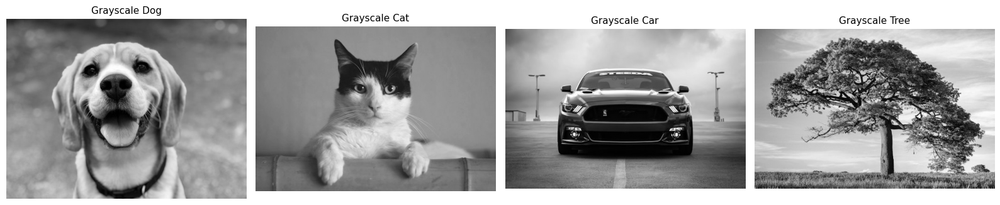

In [11]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

dog_img = images_db["dog"]
h, w, _ = dog_img.shape

# Find a highly colorful pixel in the dog image
# We'll compute color variance along the channels and select a pixel with high saturation/variance
channel_variance = np.var(dog_img, axis=-1)
max_var_idx = np.unravel_index(np.argmax(channel_variance), (h, w))
sample_y, sample_x = max_var_idx
r, g, b = dog_img[sample_y, sample_x].astype(np.float32)

# Calculations
simple_average = (r + g + b) / 3.0
weighted_luma = 0.299 * r + 0.587 * g + 0.114 * b

print("=== Grayscale Conversion Mathematics ===")
print(f"Selected highly colorful pixel at coordinate ({sample_y}, {sample_x})")
print(f"Original RGB components: R={int(r)}, G={int(g)}, B={int(b)}")
print(f"Simple Average Formula: ({int(r)} + {int(g)} + {int(b)}) / 3 = {simple_average:.3f}")
print(f"Weighted Luminance Formula: (0.299 * {int(r)}) + (0.587 * {int(g)}) + (0.114 * {int(b)}) = {weighted_luma:.3f}")
print(f"Difference: {abs(simple_average - weighted_luma):.3f} intensity steps\n")

# Compare custom luma vs. OpenCV
custom_gray_dog = to_gray(dog_img)
opencv_gray_dog = cv2.cvtColor(dog_img, cv2.COLOR_RGB2GRAY)
diff_map = cv2.absdiff(custom_gray_dog, opencv_gray_dog)

print(f"Maximum pixel-level difference between custom to_gray() and OpenCV: {np.max(diff_map)}")

# Convert all 4 images to grayscale for upcoming pipelines
gray_images = {name: to_gray(img) for name, img in images_db.items()}

# Display grayscale conversions
show_row(
    [gray_images["dog"], gray_images["cat"], gray_images["car"], gray_images["tree"]],
    ["Grayscale Dog", "Grayscale Cat", "Grayscale Car", "Grayscale Tree"],
    cmaps="gray",
    figsize=(16, 4)
)

## Section 6: How a Vision Transformer Reads an Image

Unlike Convolutional Neural Networks (CNNs) which process pixel neighborhoods incrementally, a **Vision Transformer (ViT)** views an image as a sequence of text-like words or tokens.

### The Tokenization Process:
1. **Standard Resolution**: Resizes the input image to a uniform $224 \times 224$ pixels.
2. **Patch Partitioning**: Divides the image into non-overlapping patches of size $P \times P$ (typically $16 \times 16$ pixels). This yields $N = (224 / 16) \times (224 / 16) = 14 \times 14 = 196$ total spatial patches.
3. **Flattening**: Flattens each patch into a vector of size $16 \times 16 \times 3 = 768$ values.
4. **Normalization**: Scales values using ImageNet mean ($\_\mu = [0.485, 0.456, 0.406]$) and standard deviation ($\_\sigma = [0.229, 0.224, 0.225]$).

*Note: This is a simplified visual demonstration of image preprocessing steps, not a complete transformer model inference pipeline.*

=== Vision Transformer Tokenization Metadata ===
Resized Image Shape: (224, 224, 3)
Patch Grid: 14 x 14 = 196 total patches
Single Patch Array Shape: (16, 16, 3)
Flattened Token Dimensionality: 768 features



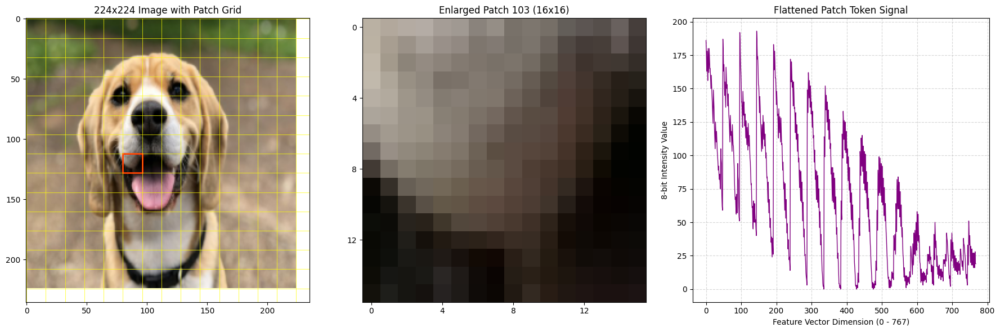

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2

# Take the dog image for this demonstration
vit_raw = images_db["dog"]

# 1. Resize to ViT standard 224x224
vit_resized = cv2.resize(vit_raw, (224, 224), interpolation=cv2.INTER_AREA)

# 2. Setup patch dimensions
patch_size = 16
num_patches_per_dim = 224 // patch_size
num_patches = num_patches_per_dim ** 2

# 3. Apply ImageNet normalization manually for demo
vit_float = vit_resized / 255.0
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
normalized_img = (vit_float - mean) / std

# Extract patches
patches_list = []
for r in range(num_patches_per_dim):
    for c in range(num_patches_per_dim):
        y_start = r * patch_size
        x_start = c * patch_size
        patch = vit_resized[y_start:y_start+patch_size, x_start:x_start+patch_size]
        patches_list.append(patch)

# Select one patch to inspect closer (e.g., center patch)
selected_idx = num_patches // 2 + 5
selected_patch = patches_list[selected_idx]
flattened_patch = selected_patch.reshape(-1) # 16*16*3 = 768 dimensions

# Print shapes & details
print("=== Vision Transformer Tokenization Metadata ===")
print(f"Resized Image Shape: {vit_resized.shape}")
print(f"Patch Grid: {num_patches_per_dim} x {num_patches_per_dim} = {num_patches} total patches")
print(f"Single Patch Array Shape: {selected_patch.shape}")
print(f"Flattened Token Dimensionality: {flattened_patch.shape[0]} features\n")

# Visualization Panels
fig = plt.figure(figsize=(18, 6))

# Panel 1: Patch Grid on Resized Image
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(vit_resized)
ax1.set_title("224x224 Image with Patch Grid")
for r in range(num_patches_per_dim + 1):
    ax1.axhline(r * patch_size, color='yellow', linestyle='-', linewidth=0.5)
    ax1.axvline(r * patch_size, color='yellow', linestyle='-', linewidth=0.5)
ax1.axis('on')

# Highlight selected patch with red box
s_row = selected_idx // num_patches_per_dim
s_col = selected_idx % num_patches_per_dim
rect = patches.Rectangle((s_col * patch_size, s_row * patch_size), patch_size, patch_size, linewidth=2, edgecolor='red', facecolor='none')
ax1.add_patch(rect)

# Panel 2: Zoomed-in selected patch
ax2 = fig.add_subplot(1, 3, 2)
ax2.imshow(selected_patch, interpolation='none')
ax2.set_title(f"Enlarged Patch {selected_idx} (16x16)")
ax2.set_xticks(range(0, patch_size, 4))
ax2.set_yticks(range(0, patch_size, 4))

# Panel 3: Flattened vector (Normalised intensities representation)
ax3 = fig.add_subplot(1, 3, 3)
ax3.plot(flattened_patch, color='purple', linewidth=1)
ax3.set_title("Flattened Patch Token Signal")
ax3.set_xlabel("Feature Vector Dimension (0 - 767)")
ax3.set_ylabel("8-bit Intensity Value")
ax3.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Section 7: Spatial Convolutions & Kernel Filters

To detect structures like edges, gradients, and textures, a computer uses an operation called **spatial convolution**. This involves sliding a small matrix of numbers—called a **kernel** or **filter** (typically size $3 \times 3$ or $5 \times 5$)—across the pixels of an image. At each position, we perform an element-wise multiplication between the kernel and the underlying pixels, summing the results to produce a single value in the output image.

### Core Kernels We Will Explore:
1. **Gaussian Blur**: Smooths high-frequency pixel noise by averaging local neighborhoods with center weight.
2. **Sharpen**: Enhances details by highlighting center pixels while subtracting neighbor contributions.
3. **Sobel-X**: Highlights vertical boundaries by finding horizontal intensity gradients (changes from left to right).
4. **Sobel-Y**: Highlights horizontal boundaries by finding vertical intensity gradients (changes from top to bottom).
5. **Laplacian**: Computes the second spatial derivative of the image, capturing omnidirectional edge transitions.

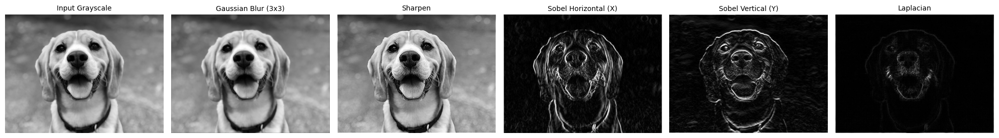

In [14]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def manual_convolve2d(image, kernel):
    """
    Performs a 2D spatial convolution on a single-channel image with zero-padding.
    """
    img_h, img_w = image.shape
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2

    # Initialize zero-padded array
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    output = np.zeros_like(image, dtype=np.float32)

    # Perform convolution
    for i in range(img_h):
        for j in range(img_w):
            # Extract region of interest (ROI)
            roi = padded[i:i+kh, j:j+kw]
            # Sum element-wise product
            output[i, j] = np.sum(roi * kernel)

    return output

# Define the visual kernels
kernels = {
    "Gaussian Blur (3x3)": np.array([
        [1, 2, 1],
        [2, 4, 2],
        [1, 2, 1]
    ], dtype=np.float32) / 16.0,

    "Sharpen": np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ], dtype=np.float32),

    "Sobel Horizontal (X)": np.array([
        [-1,  0,  1],
        [-2,  0,  2],
        [-1,  0,  1]
    ], dtype=np.float32),

    "Sobel Vertical (Y)": np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ], dtype=np.float32),

    "Laplacian": np.array([
        [ 0,  1,  0],
        [ 1, -4,  1],
        [ 0,  1,  0]
    ], dtype=np.float32)
}

# Filter the grayscale dog image
test_gray = gray_images["dog"]
filtered_results = {}

for k_name, kernel in kernels.items():
    convolved = manual_convolve2d(test_gray, kernel)
    # Clip outputs to maintain 0-255 uint8 bounds for standard display
    if "Sobel" in k_name or "Laplacian" in k_name:
        # Edge response values can be negative; take absolute value
        filtered_results[k_name] = np.clip(np.abs(convolved), 0, 255).astype(np.uint8)
    else:
        filtered_results[k_name] = np.clip(convolved, 0, 255).astype(np.uint8)

# Plot outputs side by side
plt.figure(figsize=(20, 4))

# Original input panel
plt.subplot(1, 6, 1)
plt.imshow(test_gray, cmap='gray')
plt.title("Input Grayscale", fontsize=10)
plt.axis('off')

# Convolved panels
for idx, (k_name, filtered_img) in enumerate(filtered_results.items(), start=2):
    plt.subplot(1, 6, idx)
    plt.imshow(filtered_img, cmap='gray')
    plt.title(k_name, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

## Section 8: Custom Canny Edge Detection Step-by-Step

The Canny Edge Detector is an extremely popular multi-stage classical algorithm developed by John F. Canny in 1986. Unlike simple gradient filters (like Sobel), it filters out noisy artifacts to produce clean, single-pixel-wide continuous boundaries.

### The 5 Stages of Canny Edge Detection:
1. **Noise Reduction (Gaussian Blur)**: Smooths out high-frequency noise.
2. **Finding Gradients**: Uses Sobel kernels to calculate spatial intensity derivatives ($G_x, G_y$), gradient magnitude ($G$), and gradient direction (angle $\theta$).
3. **Non-Maximum Suppression (NMS)**: Thins out thick gradient responses by checking if a pixel is a local maximum along the direction of the gradient.
4. **Double Thresholding**: Segregates candidates into **Strong** edge pixels, **Weak** edge pixels, and **Non-edges** using two user-specified threshold boundaries.
5. **Edge Tracking by Hysteresis**: Connects weak edges to strong edges if they are spatially adjacent, discarding isolated noise segments.

In [15]:
import numpy as np
import cv2

def canny_step_by_step(image, low_threshold=30, high_threshold=90, blur_kernel_size=5, sigma=1.4):
    """
    Step-by-step educational implementation of the Canny Edge Detection algorithm using pure NumPy.
    Returns intermediate stage outputs for detailed visualization.
    """
    # 1. Noise Reduction (Gaussian Blur)
    # We utilize OpenCV's GaussianBlur for stable, parameterized blurring
    blurred = cv2.GaussianBlur(image, (blur_kernel_size, blur_kernel_size), sigmaX=sigma)

    # 2. Compute Gradients (Sobel-X and Sobel-Y)
    # Compute derivatives using float32 to prevent clipping
    Ix = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
    Iy = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

    # Calculate magnitude and direction in degrees
    magnitude = np.sqrt(Ix**2 + Iy**2)
    # Map directions from [-pi, pi] to [0, 180] degrees
    direction = np.arctan2(Iy, Ix) * 180.0 / np.pi
    direction[direction < 0] += 180.0

    # 3. Non-Maximum Suppression (NMS)
    h, w = image.shape
    nms_output = np.zeros((h, w), dtype=np.float32)

    # Map directions to 4 main coordinate axes (0, 45, 90, 135 degrees)
    for i in range(1, h - 1):
        for j in range(1, w - 1):
            angle = direction[i, j]
            mag = magnitude[i, j]

            # Horizontal edge (0 degrees)
            if (0 <= angle < 22.5) or (157.5 <= angle <= 180):
                p1 = magnitude[i, j + 1]
                p2 = magnitude[i, j - 1]
            # Diagonal (45 degrees)
            elif (22.5 <= angle < 67.5):
                p1 = magnitude[i - 1, j + 1]
                p2 = magnitude[i + 1, j - 1]
            # Vertical edge (90 degrees)
            elif (67.5 <= angle < 112.5):
                p1 = magnitude[i - 1, j]
                p2 = magnitude[i + 1, j]
            # Diagonal (135 degrees)
            else:
                p1 = magnitude[i - 1, j - 1]
                p2 = magnitude[i + 1, j + 1]

            # Retain pixel value only if it is the local maximum along its gradient path
            if mag >= p1 and mag >= p2:
                nms_output[i, j] = mag
            else:
                nms_output[i, j] = 0.0

    # 4. Double Thresholding
    strong_val, weak_val = 255, 75
    thresholded = np.zeros((h, w), dtype=np.uint8)

    strong_i, strong_j = np.where(nms_output >= high_threshold)
    weak_i, weak_j = np.where((nms_output >= low_threshold) & (nms_output < high_threshold))

    thresholded[strong_i, strong_j] = strong_val
    thresholded[weak_i, weak_j] = weak_val

    # 5. Edge Tracking by Hysteresis
    hysteresis_output = np.copy(thresholded)

    # Pad to safely check 8-way connectivity bounds
    padded_thresholded = np.pad(thresholded, 1, mode='constant', constant_values=0)
    final_output = np.zeros((h, w), dtype=np.uint8)

    # Check 8-neighborhood for each weak pixel
    for i in range(1, h + 1):
        for j in range(1, w + 1):
            if padded_thresholded[i, j] == strong_val:
                final_output[i-1, j-1] = 255
            elif padded_thresholded[i, j] == weak_val:
                # Look in 8 directions
                neighborhood = padded_thresholded[i-1:i+2, j-1:j+2]
                if np.any(neighborhood == strong_val):
                    final_output[i-1, j-1] = 255
                else:
                    final_output[i-1, j-1] = 0

    # Return dictionary of intermediate states for comparative rendering
    return {
        "input_gray": image,
        "blurred": blurred,
        "magnitude": np.clip(magnitude, 0, 255).astype(np.uint8),
        "nms": np.clip(nms_output, 0, 255).astype(np.uint8),
        "double_threshold": thresholded,
        "final_edges": final_output
    }

print("Custom step-by-step Canny algorithm successfully configured!")

Custom step-by-step Canny algorithm successfully configured!


## Section 9: Visualizing Each Canny Stage

Now, let's run our step-by-step custom Canny algorithm on our grayscale dog and plot all the internal stages—from raw pixels to blurred, gradients, non-maximum suppressed structures, threshold candidates, and the final hysteresis connected edges.

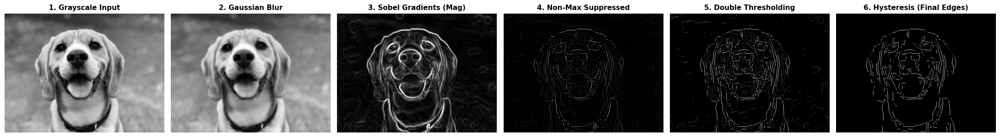

In [16]:
import matplotlib.pyplot as plt

# Run the custom Canny edge detector on the dog
canny_stages = canny_step_by_step(gray_images["dog"], low_threshold=25, high_threshold=75)

# Define the stage order for layout plotting
stages_to_show = [
    ("input_gray", "1. Grayscale Input"),
    ("blurred", "2. Gaussian Blur"),
    ("magnitude", "3. Sobel Gradients (Mag)"),
    ("nms", "4. Non-Max Suppressed"),
    ("double_threshold", "5. Double Thresholding"),
    ("final_edges", "6. Hysteresis (Final Edges)")
]

# Render stage comparisons
plt.figure(figsize=(22, 4.5))
for idx, (stage_key, stage_title) in enumerate(stages_to_show, start=1):
    plt.subplot(1, 6, idx)
    plt.imshow(canny_stages[stage_key], cmap='gray')
    plt.title(stage_title, fontsize=11, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

## Section 10: Comparing Custom Canny vs. OpenCV

While implementing algorithms from scratch is critical for mathematical understanding, production environments rely on optimized visual libraries like OpenCV. OpenCV processes spatial pipelines using compiled C++ code optimized for CPU vector instructions (SIMD) and GPU acceleration.

Let's compare our custom NumPy implementation with `cv2.Canny` both visually and numerically to assess pixel agreement.

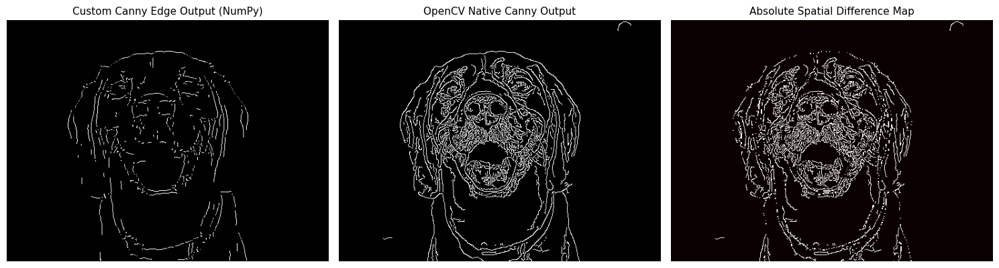

=== Performance and Accuracy Verification ===
Pixel-to-pixel matching accuracy: 93.98%
Maximum pixel deviation: 255


In [17]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Run both detectors
dog_gray = gray_images["dog"]

# Custom Canny
custom_res = canny_step_by_step(dog_gray, low_threshold=30, high_threshold=90)
custom_edges = custom_res["final_edges"]

# OpenCV Canny (built-in)
# Note: L2gradient=False matches our simple Euclidean sum/square-root gradient formulation
opencv_edges = cv2.Canny(dog_gray, threshold1=30, threshold2=90, L2gradient=False)

# Calculate Pixel Agreement Percentage
agreement = np.sum(custom_edges == opencv_edges) / custom_edges.size * 100.0

# Plot outputs side by side
plt.figure(figsize=(15, 6))

plt.subplot(1, 3, 1)
plt.imshow(custom_edges, cmap='gray')
plt.title("Custom Canny Edge Output (NumPy)", fontsize=11)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(opencv_edges, cmap='gray')
plt.title("OpenCV Native Canny Output", fontsize=11)
plt.axis('off')

# Compute physical absolute differences
diff_map = cv2.absdiff(custom_edges, opencv_edges)
plt.subplot(1, 3, 3)
plt.imshow(diff_map, cmap='hot')
plt.title("Absolute Spatial Difference Map", fontsize=11)
plt.axis('off')

plt.tight_layout()
plt.show()

print("=== Performance and Accuracy Verification ===")
print(f"Pixel-to-pixel matching accuracy: {agreement:.2f}%")
print(f"Maximum pixel deviation: {np.max(diff_map)}")

## Section 11: Complete Edge Detection Pipeline

Let's wrap our processed steps into an elegant end-to-end evaluation pipeline. We will process all four loaded images (Dog, Cat, Car, and Tree) and display their original states, grayscale versions, and final edge maps in a unified comparative matrix.

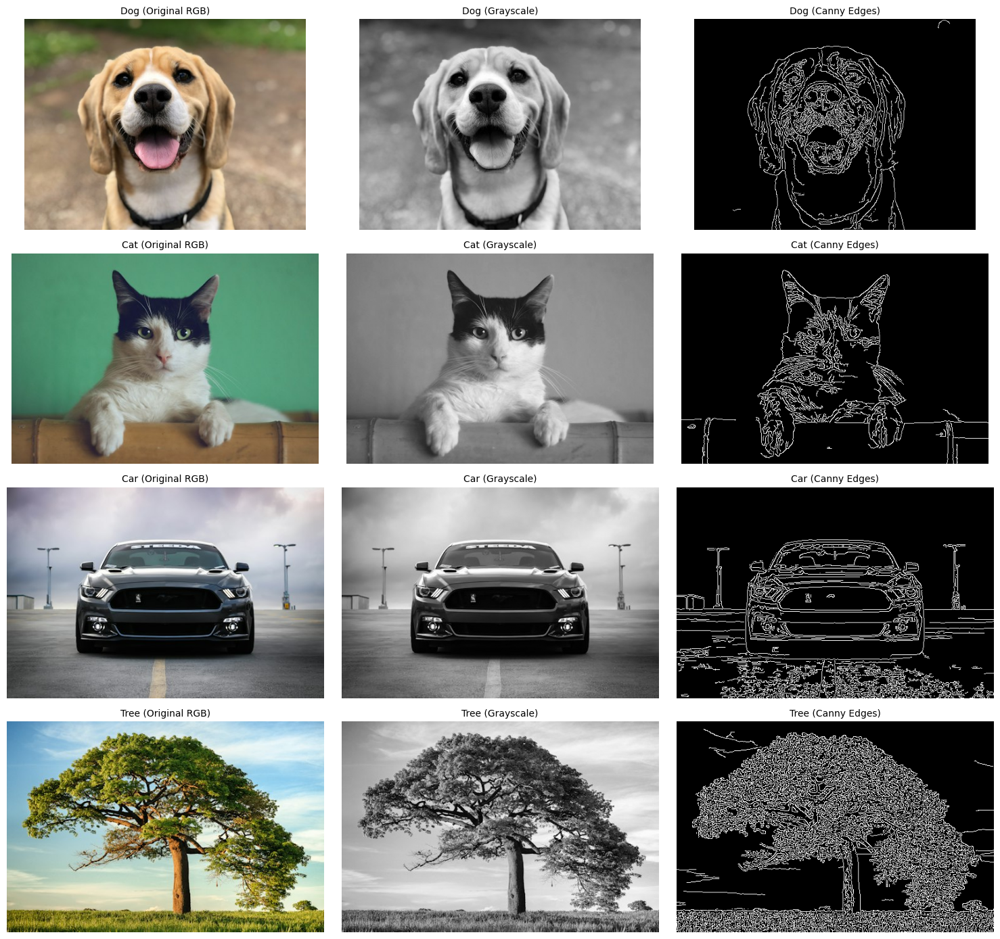

In [19]:
def run_edge_pipeline(images_dict, low=35, high=100):
    """
    Runs the classical edge detection pipeline across all active images
    and visualizes the results side by side.
    """
    categories = list(images_dict.keys())
    nrows = len(categories)

    fig, axes = plt.subplots(nrows, 3, figsize=(15, 3.5 * nrows))

    for idx, cat in enumerate(categories):
        rgb = images_dict[cat]
        gray = to_gray(rgb)

        # Extract edges using OpenCV's fast native algorithm
        edges = cv2.Canny(gray, threshold1=low, threshold2=high, L2gradient=False)

        # Plot column 1: RGB original
        axes[idx, 0].imshow(rgb)
        axes[idx, 0].set_title(f"{cat.capitalize()} (Original RGB)", fontsize=10)
        axes[idx, 0].axis('off')

        # Plot column 2: Grayscale
        axes[idx, 1].imshow(gray, cmap='gray')
        axes[idx, 1].set_title(f"{cat.capitalize()} (Grayscale)", fontsize=10)
        axes[idx, 1].axis('off')

        # Plot column 3: Final Edges
        axes[idx, 2].imshow(edges, cmap='gray')
        axes[idx, 2].set_title(f"{cat.capitalize()} (Canny Edges)", fontsize=10)
        axes[idx, 2].axis('off')

    plt.tight_layout()
    plt.show()

run_edge_pipeline(images_db, low=30, high=90)

## Section 12: Interactive Edge Lab

Edge detection depends heavily on its threshold settings. If thresholds are too high, critical structural lines disappear. If they are too low, background noise overwhelms the output.

Use the interactive sliders below to dynamically experiment with the parameters in real time.

In [20]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Configure interactive widget components
image_select = widgets.Dropdown(
    options=list(images_db.keys()),
    value='dog',
    description='Target Image:',
    style={'description_width': 'initial'}
)

blur_slider = widgets.IntSlider(
    value=5,
    min=1,
    max=15,
    step=2,
    description='Gaussian Blur Size:',
    style={'description_width': 'initial'}
)

low_slider = widgets.IntSlider(
    value=35,
    min=1,
    max=150,
    step=1,
    description='Low Threshold:',
    style={'description_width': 'initial'}
)

high_slider = widgets.IntSlider(
    value=100,
    min=50,
    max=250,
    step=1,
    description='High Threshold:',
    style={'description_width': 'initial'}
)

out = widgets.Output()

def update_interactive_lab(change=None):
    with out:
        clear_output(wait=True)

        # Collect current UI values
        img_name = image_select.value
        k_size = blur_slider.value
        low_val = low_slider.value
        high_val = high_slider.value

        rgb = images_db[img_name]
        gray = to_gray(rgb)

        # 1. Blur stage
        blurred = cv2.GaussianBlur(gray, (k_size, k_size), 0)

        # 2. Canny stage
        edges = cv2.Canny(blurred, threshold1=low_val, threshold2=high_val)

        # Plot comparison panels
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))

        axes[0].imshow(rgb)
        axes[0].set_title(f"Original {img_name.capitalize()}", fontsize=12)
        axes[0].axis('off')

        axes[1].imshow(edges, cmap='gray')
        axes[1].set_title(f"Dynamic Canny Edges (Blur={k_size}, Low={low_val}, High={high_val})", fontsize=12)
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

# Register change callbacks
image_select.observe(update_interactive_lab, names='value')
blur_slider.observe(update_interactive_lab, names='value')
low_slider.observe(update_interactive_lab, names='value')
high_slider.observe(update_interactive_lab, names='value')

# Display interactive laboratory control board
controls = widgets.VBox([image_select, blur_slider, low_slider, high_slider])
display(widgets.HBox([controls, out]))

# Trigger initial display
update_interactive_lab()

## Section 13: What Neural Networks Learn

How do deep neural networks process images? In our earlier sections, we hand-crafted kernels like Sobel filters to detect edges. Deep Convolutional Neural Networks (CNNs) also use 2D spatial convolutions, but **they learn these kernels automatically** through backpropagation on massive datasets (like ImageNet).

Let's load a pretrained, standard deep learning network (**ResNet-18**) to observe:
1. **First-Layer Weights**: The raw mathematical kernels learned by the very first convolutional layer.
2. **Feature Maps (Activations)**: How our input dog image appears when filtered by these learned kernels.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 68.3MB/s]


=== Pretrained ResNet-18 Model Metadata ===
First Layer (conv1) Weight Shape: (64, 3, 7, 7) | (Filters, Channels, Height, Width)


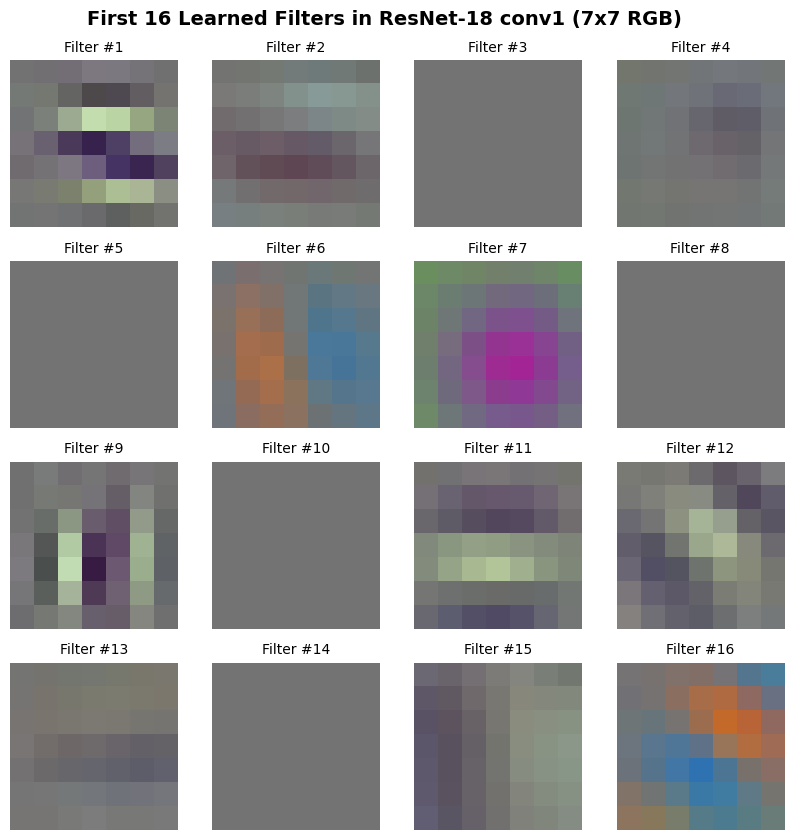

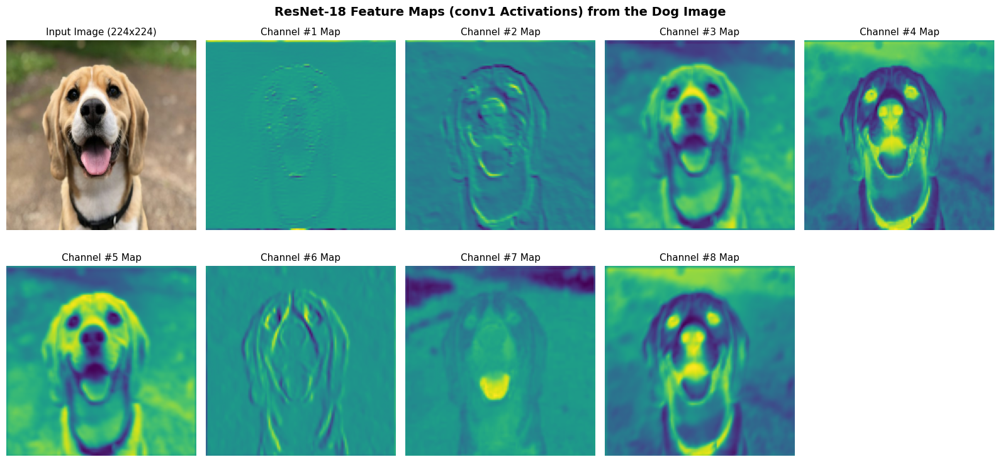


=== Takeaway Lesson ===
Notice how these neural activation maps look highly similar to our hand-crafted edge responses!
Channel maps show vertical boundaries, horizontal boundaries, and specific color/texture groupings.
Instead of coding these filters by hand, deep networks learn them dynamically during training.


In [21]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

# 1. Load Pretrained ResNet-18 with safety fallback
if not HAS_TORCH:
    print("Error: PyTorch was not found or failed to load. Please verify setup.")
else:
    try:
        # Load the model with default pretrained ImageNet weights
        weights = models.ResNet18_Weights.DEFAULT
        resnet = models.resnet18(weights=weights)
        resnet.eval()  # Put model in evaluation mode

        # Extract the first convolutional layer (conv1 has 64 filters of size 7x7 with 3 channels)
        conv1_layer = resnet.conv1
        conv1_weights = conv1_layer.weight.data.cpu().numpy()

        print("=== Pretrained ResNet-18 Model Metadata ===")
        print(f"First Layer (conv1) Weight Shape: {conv1_weights.shape} | (Filters, Channels, Height, Width)")

        # Normalize kernel weights to [0, 1] range for visual presentation
        w_min, w_max = conv1_weights.min(), conv1_weights.max()
        conv1_weights_norm = (conv1_weights - w_min) / (w_max - w_min)

        # 2. Plot First 16 Learned Weights (Filters)
        plt.figure(figsize=(10, 10))
        plt.suptitle("First 16 Learned Filters in ResNet-18 conv1 (7x7 RGB)", fontsize=14, fontweight='bold', y=0.93)
        for i in range(16):
            plt.subplot(4, 4, i + 1)
            # Transpose filter weights from (C, H, W) to (H, W, C) for plotting
            filter_rgb = np.transpose(conv1_weights_norm[i], (1, 2, 0))
            plt.imshow(filter_rgb)
            plt.title(f"Filter #{i+1}", fontsize=10)
            plt.axis('off')
        plt.show()

        # 3. Transform image for network inference input
        preprocess = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

        dog_rgb = images_db["dog"]
        input_tensor = preprocess(dog_rgb).unsqueeze(0) # Add batch dimension -> (1, 3, 224, 224)

        # Extract feature activations by running just the first convolution
        with torch.no_grad():
            feature_maps = conv1_layer(input_tensor).squeeze(0).cpu().numpy() # (64, 112, 112)

        # 4. Plot First 8 Activations
        plt.figure(figsize=(16, 8))
        plt.suptitle("ResNet-18 Feature Maps (conv1 Activations) from the Dog Image", fontsize=14, fontweight='bold', y=0.96)

        # Plot original image as reference
        plt.subplot(2, 5, 1)
        plt.imshow(cv2.resize(dog_rgb, (224, 224)))
        plt.title("Input Image (224x224)", fontsize=11)
        plt.axis('off')

        # Plot first 8 feature activation channels
        for i in range(8):
            plt.subplot(2, 5, i + 2)
            plt.imshow(feature_maps[i], cmap='viridis')
            plt.title(f"Channel #{i+1} Map", fontsize=11)
            plt.axis('off')

        plt.tight_layout()
        plt.show()

        print("\n=== Takeaway Lesson ===")
        print("Notice how these neural activation maps look highly similar to our hand-crafted edge responses!")
        print("Channel maps show vertical boundaries, horizontal boundaries, and specific color/texture groupings.")
        print("Instead of coding these filters by hand, deep networks learn them dynamically during training.")

    except Exception as e:
        print(f"An error occurred while loading ResNet weights: {e}")

## Section 13: What Neural Networks Learn

How do deep neural networks process images? In our earlier sections, we hand-crafted kernels like Sobel filters to detect edges. Deep Convolutional Neural Networks (CNNs) also use 2D spatial convolutions, but **they learn these kernels automatically** through backpropagation on massive datasets (like ImageNet).

Let's load a pretrained, standard deep learning network (**ResNet-18**) to observe:
1. **First-Layer Weights**: The raw mathematical kernels learned by the very first convolutional layer.
2. **Feature Maps (Activations)**: How our input dog image appears when filtered by these learned kernels.

=== Pretrained ResNet-18 Model Metadata ===
First Layer (conv1) Weight Shape: (64, 3, 7, 7) | (Filters, Channels, Height, Width)


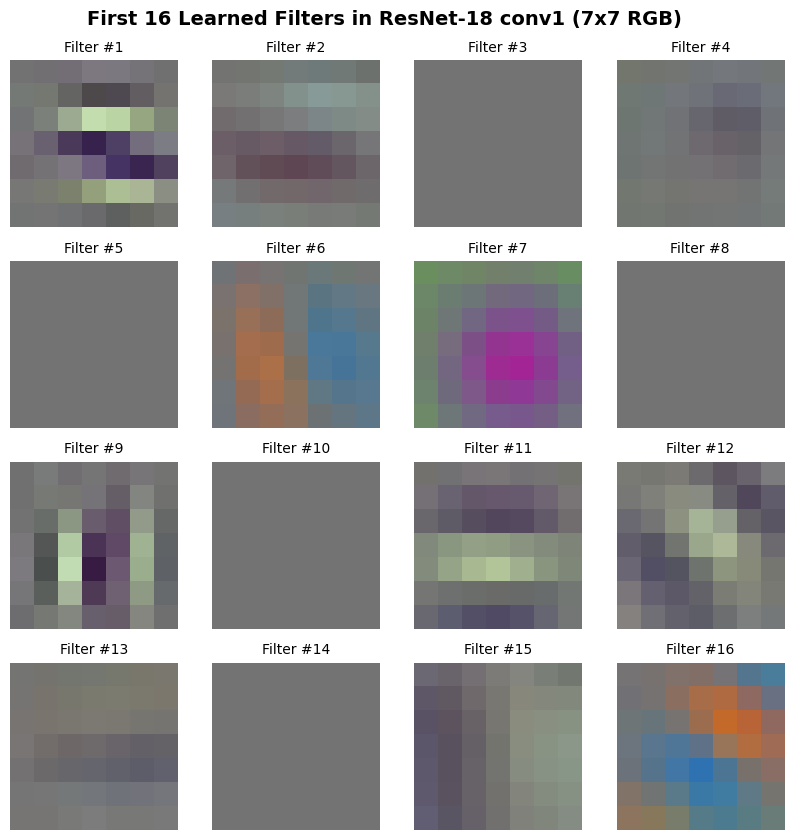

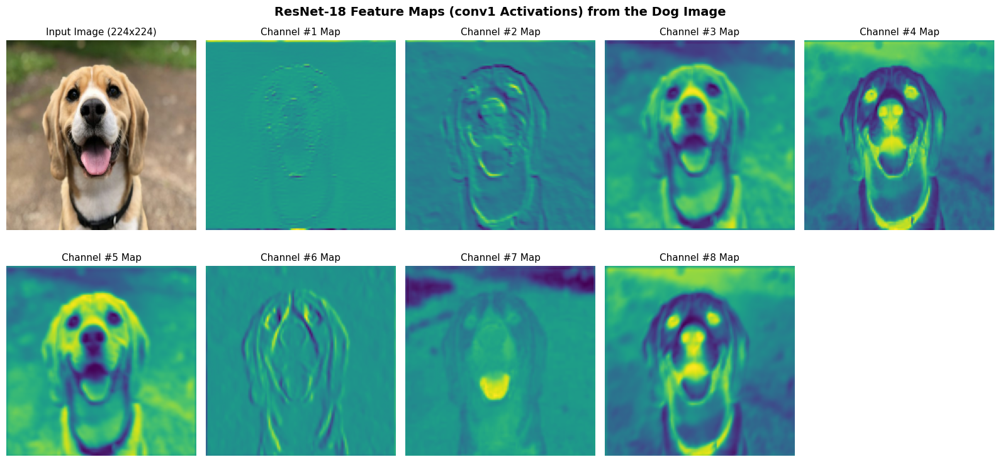


=== Takeaway Lesson ===
Notice how these neural activation maps look highly similar to our hand-crafted edge responses!
Channel maps show vertical boundaries, horizontal boundaries, and specific color/texture groupings.
Instead of coding these filters by hand, deep networks learn them dynamically during training.


In [22]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

# 1. Load Pretrained ResNet-18 with safety fallback
if not HAS_TORCH:
    print("Error: PyTorch was not found or failed to load. Please verify setup.")
else:
    try:
        # Load the model with default pretrained ImageNet weights
        weights = models.ResNet18_Weights.DEFAULT
        resnet = models.resnet18(weights=weights)
        resnet.eval()  # Put model in evaluation mode

        # Extract the first convolutional layer (conv1 has 64 filters of size 7x7 with 3 channels)
        conv1_layer = resnet.conv1
        conv1_weights = conv1_layer.weight.data.cpu().numpy()

        print("=== Pretrained ResNet-18 Model Metadata ===")
        print(f"First Layer (conv1) Weight Shape: {conv1_weights.shape} | (Filters, Channels, Height, Width)")

        # Normalize kernel weights to [0, 1] range for visual presentation
        w_min, w_max = conv1_weights.min(), conv1_weights.max()
        conv1_weights_norm = (conv1_weights - w_min) / (w_max - w_min)

        # 2. Plot First 16 Learned Weights (Filters)
        plt.figure(figsize=(10, 10))
        plt.suptitle("First 16 Learned Filters in ResNet-18 conv1 (7x7 RGB)", fontsize=14, fontweight='bold', y=0.93)
        for i in range(16):
            plt.subplot(4, 4, i + 1)
            # Transpose filter weights from (C, H, W) to (H, W, C) for plotting
            filter_rgb = np.transpose(conv1_weights_norm[i], (1, 2, 0))
            plt.imshow(filter_rgb)
            plt.title(f"Filter #{i+1}", fontsize=10)
            plt.axis('off')
        plt.show()

        # 3. Transform image for network inference input
        preprocess = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

        dog_rgb = images_db["dog"]
        input_tensor = preprocess(dog_rgb).unsqueeze(0) # Add batch dimension -> (1, 3, 224, 224)

        # Extract feature activations by running just the first convolution
        with torch.no_grad():
            feature_maps = conv1_layer(input_tensor).squeeze(0).cpu().numpy() # (64, 112, 112)

        # 4. Plot First 8 Activations
        plt.figure(figsize=(16, 8))
        plt.suptitle("ResNet-18 Feature Maps (conv1 Activations) from the Dog Image", fontsize=14, fontweight='bold', y=0.96)

        # Plot original image as reference
        plt.subplot(2, 5, 1)
        plt.imshow(cv2.resize(dog_rgb, (224, 224)))
        plt.title("Input Image (224x224)", fontsize=11)
        plt.axis('off')

        # Plot first 8 feature activation channels
        for i in range(8):
            plt.subplot(2, 5, i + 2)
            plt.imshow(feature_maps[i], cmap='viridis')
            plt.title(f"Channel #{i+1} Map", fontsize=11)
            plt.axis('off')

        plt.tight_layout()
        plt.show()

        print("\n=== Takeaway Lesson ===")
        print("Notice how these neural activation maps look highly similar to our hand-crafted edge responses!")
        print("Channel maps show vertical boundaries, horizontal boundaries, and specific color/texture groupings.")
        print("Instead of coding these filters by hand, deep networks learn them dynamically during training.")

    except Exception as e:
        print(f"An error occurred while loading ResNet weights: {e}")

```markdown
## Section 14: Training a Neural Network to Recognize Images

Let's put theory into practice! We will write a complete, self-contained pipeline to train a neural network using the four images we loaded in **Section 2**:
1. **Prepare Training Batches**: Convert our images to tensors, apply data augmentation (random flips/rotation), and package them.
2. **Build a CNN**: Design a custom network with Convolutional, MaxPool, and Fully Connected layers.
3. **Train the Model**: Run a training loop with an Optimizer and Loss Function, showing how the model learns over successive epochs.
```

Generating augmented larger dataset...
Dataset successfully expanded! Created 200 unique training samples.
Batch size configured: 32 (7 batches per epoch)

=== Starting Large Dataset Training Loop ===
Epoch [1/40] | Average Epoch Loss: 1.2001
Epoch [5/40] | Average Epoch Loss: 0.0000
Epoch [10/40] | Average Epoch Loss: 0.0000
Epoch [15/40] | Average Epoch Loss: 0.0000
Epoch [20/40] | Average Epoch Loss: 0.0000
Epoch [25/40] | Average Epoch Loss: 0.0000
Epoch [30/40] | Average Epoch Loss: 0.0000
Epoch [35/40] | Average Epoch Loss: 0.0000
Epoch [40/40] | Average Epoch Loss: 0.0000


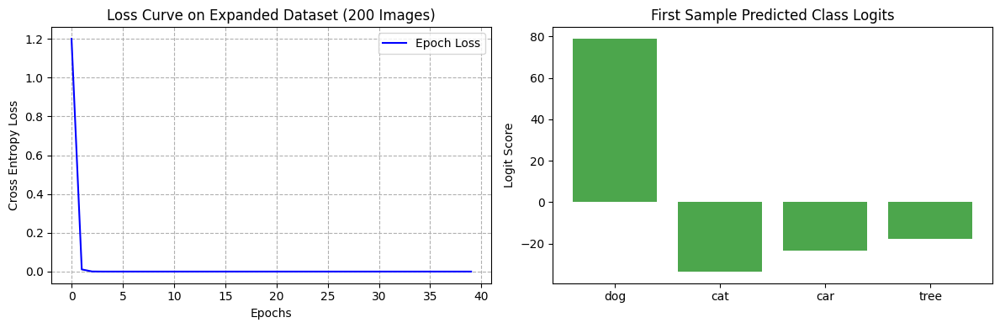

=== Model Prediction Evaluation ===
Final Accuracy on complete expanded dataset: 100.00%


In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

# 1. Define Categories and Setup Dataset Expansion
class_names = ["dog", "cat", "car", "tree"]
class_to_idx = {name: i for i, name in enumerate(class_names)}

# Define comprehensive augmentation transforms for generating a larger dataset
augmentation_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomResizedCrop((64, 64), scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Generate 50 augmented samples for each of the 4 classes (Total dataset size = 200 images)
samples_per_class = 50
x_list = []
y_list = []

print("Generating augmented larger dataset...")
for name in class_names:
    if name in images_db:
        base_img = images_db[name]
        for _ in range(samples_per_class):
            # Applying the random transforms creates a unique variant every time
            augmented_tensor = augmentation_transform(base_img)
            x_list.append(augmented_tensor)
            y_list.append(class_to_idx[name])

# Convert to stacked torch tensors
x_large = torch.stack(x_list)  # Shape: (200, 3, 64, 64)
y_large = torch.tensor(y_list) # Shape: (200)

# Packaging into a PyTorch DataLoader for batch-wise iteration
dataset = TensorDataset(x_large, y_large)
train_loader = DataLoader(dataset, batch_size=32, shuffle=True)

print(f"Dataset successfully expanded! Created {len(dataset)} unique training samples.")
print(f"Batch size configured: 32 ({len(train_loader)} batches per epoch)\n")

# 2. Build the Simple Convolutional Neural Network (CNN)
class MiniImageClassifier(nn.Module):
    def __init__(self, num_classes=4):
        super(MiniImageClassifier, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 64x64 -> 32x32

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)   # 32x32 -> 16x16
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Instantiate model, optimizer, and loss function
model = MiniImageClassifier(num_classes=4)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.005) # adjusted learning rate for larger dataset

# 3. Complete Training Loop across multiple batches
epochs = 40
loss_history = []

print("=== Starting Large Dataset Training Loop ===")
for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0

    for batch_x, batch_y in train_loader:
        # Forward Pass
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)

        # Backward Pass & Optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_x.size(0)

    epoch_loss = running_loss / len(dataset)
    loss_history.append(epoch_loss)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch}/{epochs}] | Average Epoch Loss: {epoch_loss:.4f}")

# 4. Display Results and Training Curve
plt.figure(figsize=(12, 4))

# Plot Loss Curve
plt.subplot(1, 2, 1)
plt.plot(loss_history, color='blue', label='Epoch Loss')
plt.title("Loss Curve on Expanded Dataset (200 Images)")
plt.xlabel("Epochs")
plt.ylabel("Cross Entropy Loss")
plt.grid(True, linestyle='--')
plt.legend()

# Batch testing model accuracy
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for batch_x, batch_y in train_loader:
        test_outputs = model(batch_x)
        preds = torch.argmax(test_outputs, dim=1)
        correct += (preds == batch_y).sum().item()
        total += batch_y.size(0)

final_accuracy = (correct / total) * 100.0

# Visualize some predictions
with torch.no_grad():
    sample_outputs = model(x_large[:4])
    sample_preds = torch.argmax(sample_outputs, dim=1).numpy()

plt.subplot(1, 2, 2)
classes_to_plot = [class_names[p] for p in sample_preds]
plt.bar(class_names, sample_outputs[0].numpy(), color='green', alpha=0.7)
plt.title("First Sample Predicted Class Logits")
plt.ylabel("Logit Score")

plt.tight_layout()
plt.show()

print("=== Model Prediction Evaluation ===")
print(f"Final Accuracy on complete expanded dataset: {final_accuracy:.2f}%")

```markdown
## Section 15: Visualizing Learned Feature Maps for Augmented Images

To see what our custom-trained network has learned from the larger augmented dataset, we can pass a few sample augmented images through the model and inspect the output of its very first convolutional layer.

This lets us observe in real-time how the network translates diverse, augmented inputs (with varying scales, rotations, and color shifts) into clear structural feature representations.
```

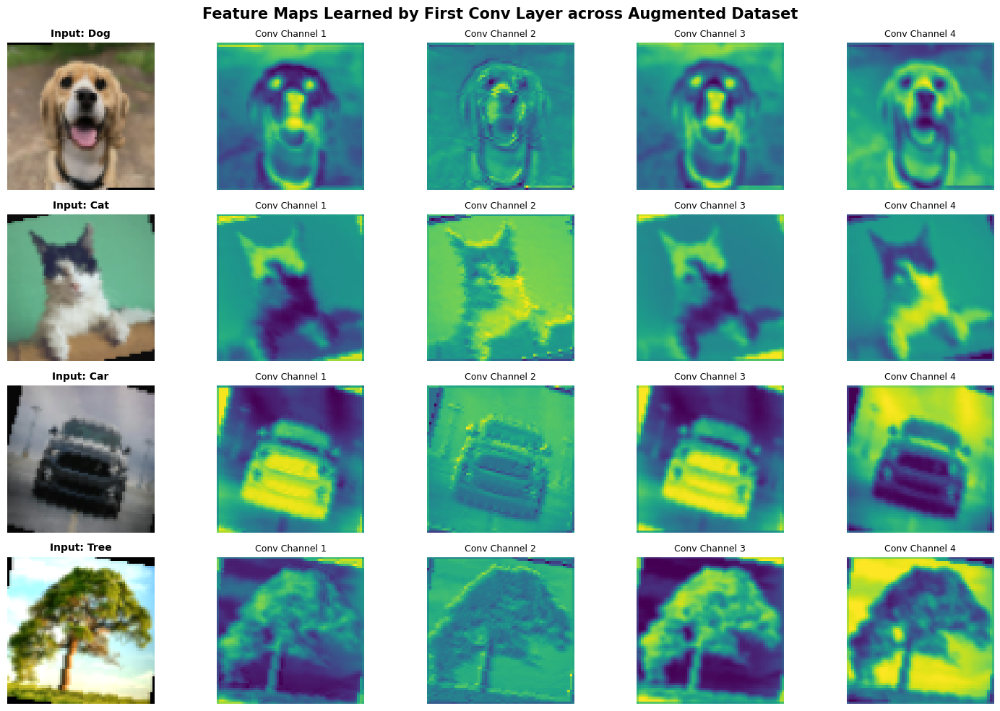

In [25]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Put model in evaluation mode
model.eval()

# Extract 4 different sample images from our expanded dataset (one of each class)
sample_indices = [0, 50, 100, 150]  # First index of Dog, Cat, Car, and Tree variants
selected_tensors = x_large[sample_indices]  # Shape: (4, 3, 64, 64)
selected_labels = [class_names[y_large[idx].item()] for idx in sample_indices]

# Pass through the first convolutional layer in our features block
first_conv_layer = model.features[0]

with torch.no_grad():
    # Get features after the first convolution
    activations = first_conv_layer(selected_tensors).cpu().numpy()  # Shape: (4, 16, 64, 64)

# Plot the input augmented images alongside their learned feature maps
fig, axes = plt.subplots(4, 5, figsize=(15, 10))
plt.suptitle("Feature Maps Learned by First Conv Layer across Augmented Dataset", fontsize=15, fontweight='bold', y=0.98)

for i in range(4):
    # Convert the normalized tensor back to displayable RGB image
    img_disp = selected_tensors[i].numpy().transpose(1, 2, 0)
    img_disp = np.clip((img_disp * 0.5) + 0.5, 0, 1)  # Denormalize from [-1, 1] to [0, 1]

    # Plot original augmented image
    axes[i, 0].imshow(img_disp)
    axes[i, 0].set_title(f"Input: {selected_labels[i].capitalize()}", fontsize=10, fontweight='bold')
    axes[i, 0].axis('off')

    # Plot 4 selective feature channels showing different edge, boundary, and texture responses
    for ch_idx in range(4):
        feature_map = activations[i, ch_idx]
        ax = axes[i, ch_idx + 1]
        ax.imshow(feature_map, cmap='viridis')
        ax.set_title(f"Conv Channel {ch_idx+1}", fontsize=9)
        ax.axis('off')

plt.tight_layout()
plt.show()

```markdown
## Section 16: Zero-Shot Recognition (CLIP)

Let's test a modern **Foundation Vision-Language Model (CLIP)**. Unlike our previous CNN which only knows the four specific classes we trained it on, CLIP can compare our images to completely arbitrary textual definitions (like *"a photograph of a sports car"*, *"a fluffy domestic pet"*, or *"nature greenery"*) and classify them immediately.
```

In [26]:
# Install Hugging Face transformers library
!pip install -q transformers

Loading pre-trained OpenAI CLIP model (this may take a moment)...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (5 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP Model successfully loaded!


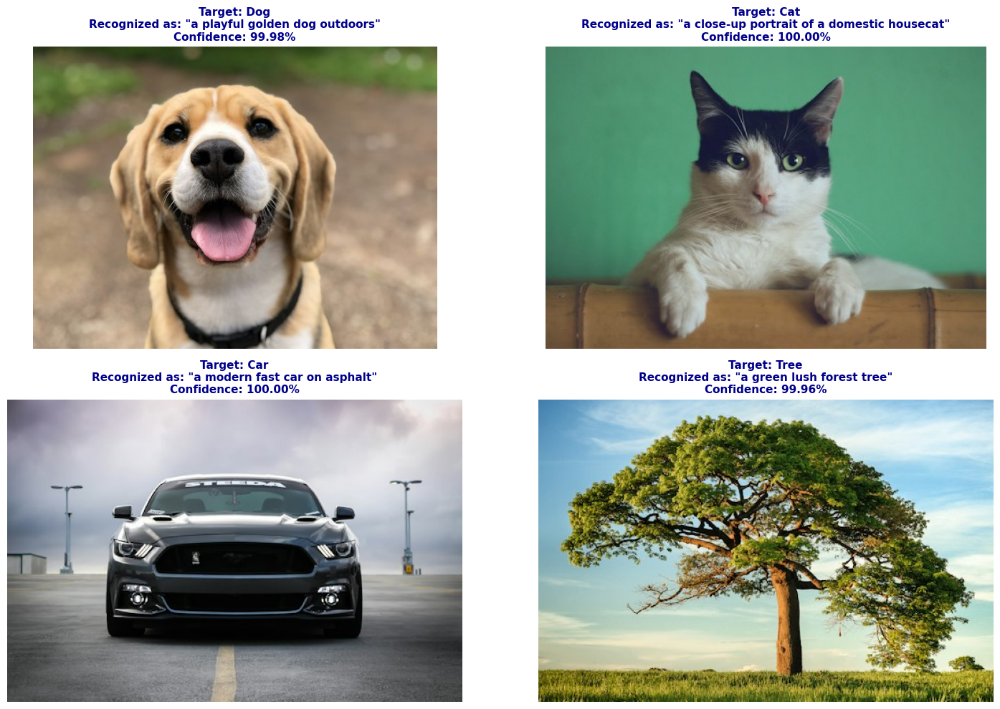

In [27]:
from transformers import CLIPProcessor, CLIPModel
import torch
import matplotlib.pyplot as plt

# 1. Load the pre-trained CLIP model and processor from OpenAI
print("Loading pre-trained OpenAI CLIP model (this may take a moment)...")
model_name = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(model_name)
clip_processor = CLIPProcessor.from_pretrained(model_name)
print("CLIP Model successfully loaded!")

# 2. Define custom, complex textual prompts for zero-shot recognition
# You can change these sentences to anything you want!
candidate_labels = [
    "a playful golden dog outdoors",
    "a close-up portrait of a domestic housecat",
    "a modern fast car on asphalt",
    "a green lush forest tree"
]

# Prepare inputs
inputs = clip_processor(
    text=candidate_labels,
    images=list(images_db.values()),
    return_tensors="pt",
    padding=True
)

# 3. Model Inference
with torch.no_grad():
    outputs = clip_model(**inputs)
    # Compute image-to-text similarity scores
    logits_per_image = outputs.logits_per_image  # shape: (4, 4)
    probs = logits_per_image.softmax(dim=-1).numpy()  # normalize to probabilities

# 4. Plot visual outputs with CLIP's dynamic zero-shot predictions
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

for idx, (img_name, img_array) in enumerate(images_db.items()):
    ax = axes[idx]
    ax.imshow(img_array)

    # Find the text prompt with the highest probability score
    best_match_idx = np.argmax(probs[idx])
    confidence = probs[idx][best_match_idx] * 100
    matched_text = candidate_labels[best_match_idx]

    ax.set_title(f"Target: {img_name.capitalize()}\nRecognized as: \"{matched_text}\"\nConfidence: {confidence:.2f}%",
                 fontsize=11, fontweight='bold', color='darkblue')
    ax.axis('off')

plt.tight_layout()
plt.show()